# Final Results: Hold-Out Evaluation

**Objective:** Evaluate the selected models **once** on the hold-out fold (fold 4), which no model, tuning step or threshold choice has used. These are the numbers to report as final performance.

**Selected models** (best mean over folds 0–3 in `classification_models.ipynb` and `regression_models.ipynb`, configuration `10km_subbasin` with subbasin features):
- Classification (exceeds 10 mg/L): **random forest** (AUC 0.827, Brier skill 0.291), with the dummy baseline for reference.
- Regression (log nitrate): **random forest** (RMSE 0.973, R² 0.343), with the dummy baseline for reference.

**Procedure**
1. Each final model is tuned and fit on all development data (folds 0–3), with exactly the same settings and search as in the model notebooks.
2. The classification threshold is fixed **before** looking at the hold-out: by default, the threshold with the best F1 on the out-of-fold predictions of folds 0–3.
3. Each model predicts fold 4 once; scores are compared with the cross-validation results.

**Rule: run the final evaluation only once, after the team agrees on the models and the threshold.** Keep `RUN_FINAL_EVALUATION = False` until then: the notebook performs a *dry run* that treats fold 3 as a stand-in test set (training on folds 0–2), so the code can be checked without touching fold 4.

In [1]:
import sys
from pathlib import Path

# Make src importable from any notebook folder (identical in every notebook)
sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())))
from src import paths

ROOT = paths.ROOT


import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.calibration import calibration_curve
from sklearn.metrics import (RocCurveDisplay, PrecisionRecallDisplay, ConfusionMatrixDisplay,
                             roc_auc_score, average_precision_score, brier_score_loss,
                             precision_score, recall_score, f1_score,
                             root_mean_squared_error, r2_score)

from src.features.preprocessing import load_model_data
from src.evaluation.make_splits import load_split
from src.evaluation.results_log import load_runs
from src.models.evaluate import tuned, all_features, predictions_path

## 0. Settings

In [2]:
RUN_FINAL_EVALUATION = True      # True only once, after the team agrees on models and threshold
SPLIT, USE_SUBBASIN = "10km_subbasin", True
THRESHOLD_MG_L = 10
THRESHOLD = 0.4                 # agreed by the team; best F1 on folds 0-3 out-of-fold predictions is 0.35-0.37
# Same grids and searches as classification_models.ipynb and regression_models.ipynb
RF_GRID = {
    "max_depth": [6, 8, 11, 15, None],
    "max_features": ["sqrt", 0.3, 0.5],
    "min_samples_leaf": [1, 5, 20],
}
CLASSIFIERS = {
    "Dummy (prior)": lambda: DummyClassifier(strategy="prior"),
    "Random forest": lambda: tuned(RandomForestClassifier(n_estimators=300, random_state=0, n_jobs=1),
                                   RF_GRID, "neg_brier_score", n_iter=10),
}
REGRESSORS = {
    "Dummy (mean)": lambda: DummyRegressor(strategy="mean"),
    "Random forest": lambda: tuned(RandomForestRegressor(n_estimators=300, random_state=0, n_jobs=1),
                                   RF_GRID, "neg_root_mean_squared_error", n_iter=10),
}

OUT_DIR = paths.FIGURES["final"]
MODEL_DIR = paths.MODELS          # fitted models (large files, not tracked by Git)
if RUN_FINAL_EVALUATION:
    OUT_DIR.mkdir(parents=True, exist_ok=True)
    MODEL_DIR.mkdir(parents=True, exist_ok=True)
TAG = "holdout" if RUN_FINAL_EVALUATION else "dry_run"
print("FINAL EVALUATION ON FOLD 4" if RUN_FINAL_EVALUATION
      else "DRY RUN: training on folds 0-2, testing on fold 3 (fold 4 is not used)")

FINAL EVALUATION ON FOLD 4


## 1. Data

Development data = folds 0–3; hold-out = fold 4. In the dry run, fold 3 plays the role of the hold-out.

In [3]:
X, y, meta = load_model_data(subbasin=USE_SUBBASIN, drop_elevation=USE_SUBBASIN)
FEATURES = list(X.columns)
data = load_split(pd.concat([meta, X], axis=1).assign(log_nitrate=y), split=SPLIT)
data["exceeds"] = (np.expm1(data["log_nitrate"]) > THRESHOLD_MG_L).astype(int)

if RUN_FINAL_EVALUATION:
    train, test = data[~data["holdout"]], data[data["holdout"]]
else:
    dev = data[~data["holdout"]]
    train, test = dev[dev["fold"] < 3], dev[dev["fold"] == 3]
train, test = train.reset_index(drop=True), test.reset_index(drop=True)

print(f"Train: {len(train):,} samples, {train.gm_well_id.nunique():,} wells (folds {sorted(train.fold.unique())})")
print(f"Test:  {len(test):,} samples, {test.gm_well_id.nunique():,} wells (fold {sorted(test.fold.unique())}) | "
      f"{test.exceeds.mean():.0%} exceed {THRESHOLD_MG_L} mg/L")

Train: 4,256 samples, 1,622 wells (folds [np.int64(0), np.int64(1), np.int64(2), np.int64(3)])
Test:  1,024 samples, 371 wells (fold [np.int64(4)]) | 42% exceed 10 mg/L


## 2. Classification threshold

Fixed by the team before the evaluation at **0.4**: the thresholds that maximize F1 on the out-of-fold predictions of folds 0–3 are 0.35–0.37 for the random forest. A threshold below 0.5 catches more exceeding wells (higher recall) at the cost of more false alarms, which suits drinking-water screening, where missing a contaminated well is worse than an extra sample.

In [4]:
if THRESHOLD is None:
    oof = pd.read_csv(predictions_path("classification", SPLIT, USE_SUBBASIN))
    candidates = np.round(np.arange(0.05, 0.951, 0.01), 2)
    f1 = [f1_score(oof["exceeds"], (oof["Random forest"] >= t).astype(int)) for t in candidates]
    THRESHOLD = float(candidates[int(np.argmax(f1))])
    print(f"Threshold chosen on folds 0-3 out-of-fold predictions: {THRESHOLD:.2f} (F1 = {max(f1):.3f})")
else:
    print(f"Threshold set by hand: {THRESHOLD:.2f}")

Threshold set by hand: 0.40


## 3. Fit the final models and predict the test fold

Searches are tuned inside the training folds only (one whole fold held out at a time), exactly as in the model notebooks.

In [5]:
def fit(make_model, target):
    model = make_model()
    is_search = hasattr(model, "best_params_") or hasattr(model, "param_distributions") or hasattr(model, "param_grid")
    model.fit(train[FEATURES], train[target], **({"groups": train["fold"]} if is_search else {}))
    if is_search:
        print(f"  best settings: {model.best_params_}")
    return model


final_models = {}

class_probs, reg_preds = {}, {}
for name, make_model in CLASSIFIERS.items():
    print(f"Classification - {name}")
    model = fit(make_model, "exceeds")
    class_probs[name] = model.predict_proba(test[FEATURES])[:, 1]
    if RUN_FINAL_EVALUATION and name == "Random forest":
        joblib.dump(model.best_estimator_, paths.FINAL_CLASSIFIER)
    if name == "Random forest":
        final_models["Random forest classifier"] = model.best_estimator_

for name, make_model in REGRESSORS.items():
    print(f"Regression - {name}")
    model = fit(make_model, "log_nitrate")
    reg_preds[name] = model.predict(test[FEATURES])
    if RUN_FINAL_EVALUATION and name == "Random forest":
        joblib.dump(model.best_estimator_, paths.FINAL_REGRESSOR)
    if name == "Random forest":
        final_models["Random forest regressor"] = model.best_estimator_

Classification - Dummy (prior)
Classification - Random forest


  best settings: {'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': 15}


Regression - Dummy (mean)
Regression - Random forest


  best settings: {'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': 15}


## 4. Scores on the test fold, compared with cross-validation

Cross-validation columns are the mean over folds 0–3 from `results/model_runs/` (same configuration). A test score close to the cross-validation mean means the model generalizes as expected to unseen areas.

In [6]:
runs = load_runs()
runs = runs[(runs["split"] == SPLIT) & (runs["use_subbasin"] == USE_SUBBASIN)]
cv_mean = runs.groupby(["task", "model"])[["auc", "brier_skill", "rmse_log", "r2"]].mean()

base_rate = train["exceeds"].mean()
brier_base = brier_score_loss(test["exceeds"], np.full(len(test), base_rate))
rows = []
for name, prob in class_probs.items():
    called = (prob >= THRESHOLD).astype(int)
    rows.append({
        "task": "classification", "model": name,
        "auc": roc_auc_score(test["exceeds"], prob),
        "brier_skill": 1 - brier_score_loss(test["exceeds"], prob) / brier_base,
        "average_precision": average_precision_score(test["exceeds"], prob),
        "recall": recall_score(test["exceeds"], called, zero_division=0),
        "precision": precision_score(test["exceeds"], called, zero_division=0),
        "f1": f1_score(test["exceeds"], called, zero_division=0),
        "cv_auc": cv_mean["auc"].get(("classification", name), np.nan),
        "cv_brier_skill": cv_mean["brier_skill"].get(("classification", name), np.nan),
    })
for name, pred in reg_preds.items():
    rows.append({
        "task": "regression", "model": name,
        "rmse_log": root_mean_squared_error(test["log_nitrate"], pred),
        "r2": r2_score(test["log_nitrate"], pred),
        "cv_rmse_log": cv_mean["rmse_log"].get(("regression", name), np.nan),
        "cv_r2": cv_mean["r2"].get(("regression", name), np.nan),
    })

final_scores = pd.DataFrame(rows).assign(threshold=THRESHOLD, evaluation=TAG)
if RUN_FINAL_EVALUATION:                       # the dry run is only a code check; nothing is saved
    final_scores.to_csv(paths.FINAL_SCORES, index=False)
display(final_scores.set_index(["task", "model"]).round(3).dropna(axis=1, how="all"))

auc  brier_skill  average_precision  recall  \
task           model                                                          
classification Dummy (prior)  0.500        0.000              0.422   0.000   
               Random forest  0.741        0.209              0.585   0.741   
regression     Dummy (mean)     NaN          NaN                NaN     NaN   
               Random forest    NaN          NaN                NaN     NaN   

                              precision     f1  cv_auc  cv_brier_skill  \
task           model                                                     
classification Dummy (prior)      0.000  0.000   0.500           0.000   
               Random forest      0.586  0.654   0.827           0.291   
regression     Dummy (mean)         NaN    NaN     NaN             NaN   
               Random forest        NaN    NaN     NaN             NaN   

                              rmse_log     r2  cv_rmse_log  cv_r2  threshold  \
task           model                                                           
classification Dummy (prior)       NaN    NaN          NaN    NaN        0.4   
               Random forest       NaN    NaN          NaN    NaN        0.4   
regression     Dummy (mean)      1.237 -0.146        1.208 -0.006        0.4   
               Random forest     1.054  0.168        0.973  0.343        0.4   

                             evaluation  
task           model                     
classification Dummy (prior)    holdout  
               Random forest    holdout  
regression     Dummy (mean)     holdout  
               Random forest    holdout

## 5. Figures

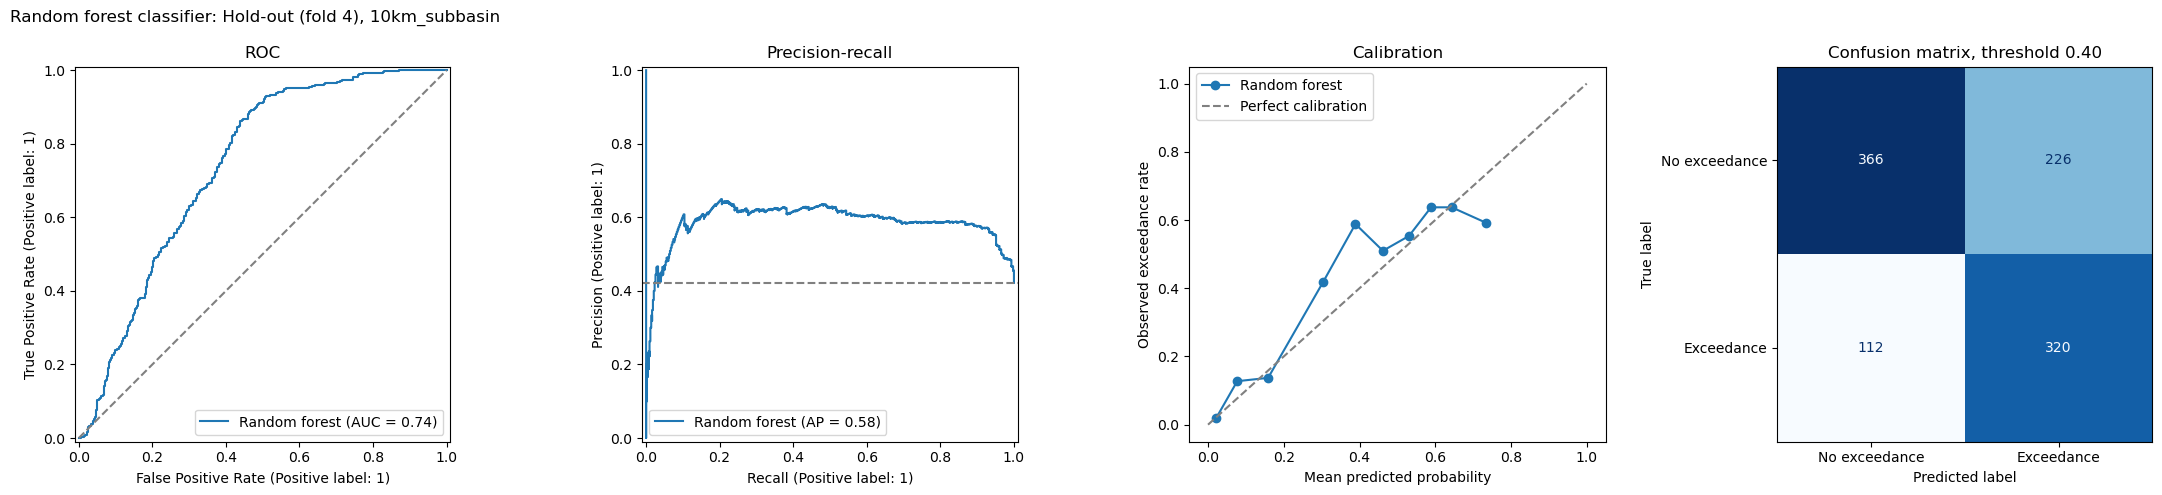

In [7]:
fig, axs = plt.subplots(1, 4, figsize=(22, 5))
rf_prob = class_probs["Random forest"]

RocCurveDisplay.from_predictions(test["exceeds"], rf_prob, name="Random forest", ax=axs[0])
axs[0].plot([0, 1], [0, 1], color="gray", linestyle="--")
axs[0].set_title("ROC")

PrecisionRecallDisplay.from_predictions(test["exceeds"], rf_prob, name="Random forest", ax=axs[1])
axs[1].axhline(test["exceeds"].mean(), color="gray", linestyle="--", label="Prevalence")
axs[1].set_title("Precision-recall")

observed, predicted = calibration_curve(test["exceeds"], rf_prob, n_bins=10, strategy="quantile")
axs[2].plot(predicted, observed, marker="o", label="Random forest")
axs[2].plot([0, 1], [0, 1], color="gray", linestyle="--", label="Perfect calibration")
axs[2].set(xlabel="Mean predicted probability", ylabel="Observed exceedance rate", title="Calibration")
axs[2].legend()

ConfusionMatrixDisplay.from_predictions(test["exceeds"], (rf_prob >= THRESHOLD).astype(int),
                                        display_labels=["No exceedance", "Exceedance"],
                                        cmap="Blues", colorbar=False, ax=axs[3])
axs[3].set_title(f"Confusion matrix, threshold {THRESHOLD:.2f}")

title = "Hold-out (fold 4)" if RUN_FINAL_EVALUATION else "DRY RUN (fold 3 as stand-in)"
fig.suptitle(f"Random forest classifier: {title}, {SPLIT}", x=0.01, ha="left")
plt.tight_layout()
if RUN_FINAL_EVALUATION:
    plt.savefig(OUT_DIR / "classification_holdout.png", dpi=150, bbox_inches="tight")
plt.show()

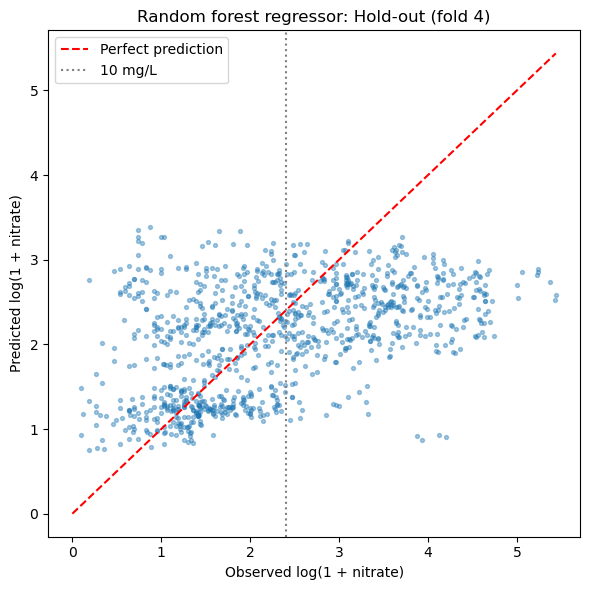

In [8]:
rf_pred = reg_preds["Random forest"]
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(test["log_nitrate"], rf_pred, s=8, alpha=0.4)
limits = [0, max(test["log_nitrate"].max(), rf_pred.max())]
ax.plot(limits, limits, color="red", linestyle="--", label="Perfect prediction")
ax.axvline(np.log1p(THRESHOLD_MG_L), color="gray", linestyle=":", label="10 mg/L")
ax.set(xlabel="Observed log(1 + nitrate)", ylabel="Predicted log(1 + nitrate)",
       title=f"Random forest regressor: {title}")
ax.legend()
plt.tight_layout()
if RUN_FINAL_EVALUATION:
    plt.savefig(OUT_DIR / "regression_holdout.png", dpi=150, bbox_inches="tight")
plt.show()

## 5b. Why the hold-out differs: where each fold is, and how the model did in each

The folds are groups of 10 km grid cells, so each fold covers different parts of the valley. These figures show (1) where each fold's wells are, (2) how much of each subbasin and how much contamination each fold contains, and (3) the random forest's score in each cross-validation fold next to the hold-out. They describe the evaluation; nothing here changes the model.

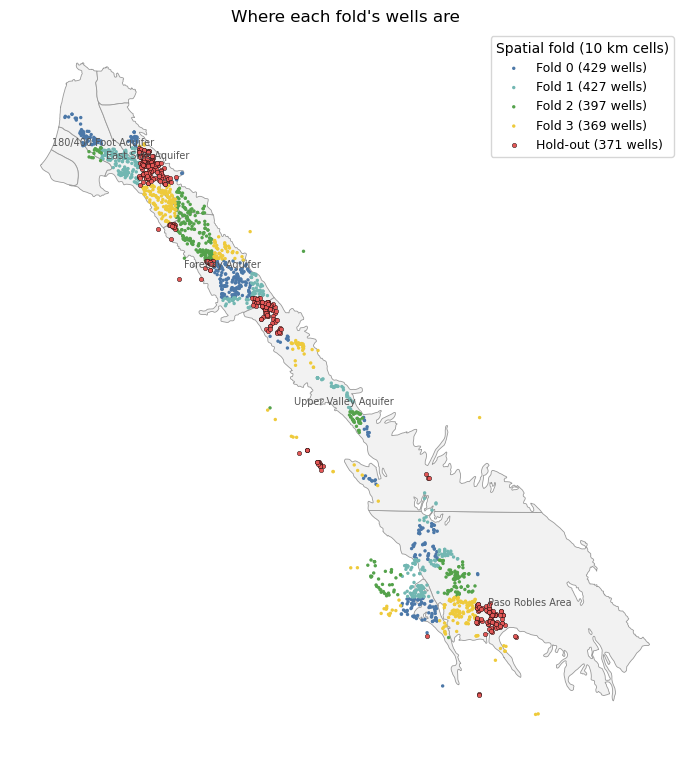

In [9]:
import geopandas as gpd
from src.features.transformers import SUBBASIN_PATH

subbasin_cols = [c for c in FEATURES if c.startswith("subbasin_")]
data["subbasin_name"] = (data[subbasin_cols].idxmax(axis=1).str.replace("subbasin_", "", regex=False)
                         .str.title().str.replace("Foot", "ft", regex=False))
data["fold_label"] = np.where(data["holdout"], "Hold-out", "Fold " + data["fold"].astype(str))
fold_order = sorted(data.loc[~data["holdout"], "fold_label"].unique()) + ["Hold-out"]
fold_colors = dict(zip(fold_order, ["#4c78a8", "#72b7b2", "#54a24b", "#eeca3b", "#e45756"]))

# 1. Map: one point per well, colored by fold
wells = data.drop_duplicates("gm_well_id")
wells = gpd.GeoDataFrame(wells, geometry=gpd.points_from_xy(wells.gm_longitude, wells.gm_latitude),
                         crs=4326).to_crs(3310)
subbasins = gpd.read_file(SUBBASIN_PATH).to_crs(3310)

fig, ax = plt.subplots(figsize=(7, 9))
subbasins.plot(ax=ax, facecolor="#f2f2f2", edgecolor="#999999", linewidth=0.6)
for label in fold_order:
    sub = wells[wells["fold_label"] == label]
    ax.scatter(sub.geometry.x, sub.geometry.y, s=10 if label == "Hold-out" else 6,
               color=fold_colors[label], label=f"{label} ({len(sub):,} wells)",
               edgecolor="black" if label == "Hold-out" else "none", linewidth=0.3)
for _, row in subbasins[subbasins.area > 150e6].iterrows():      # label the larger subbasins only
    point = row.geometry.representative_point()
    ax.annotate(str(row["Basin_Subbasin_Name"]).split(" - ")[-1].title(), (point.x, point.y),
                fontsize=7, color="#555555", ha="center")
ax.set_aspect("equal")
ax.axis("off")
ax.legend(loc="upper right", fontsize=9, title="Spatial fold (10 km cells)")
ax.set_title("Where each fold's wells are")
plt.tight_layout()
if RUN_FINAL_EVALUATION:
    plt.savefig(OUT_DIR / "folds_map.png", dpi=150, bbox_inches="tight")
plt.show()

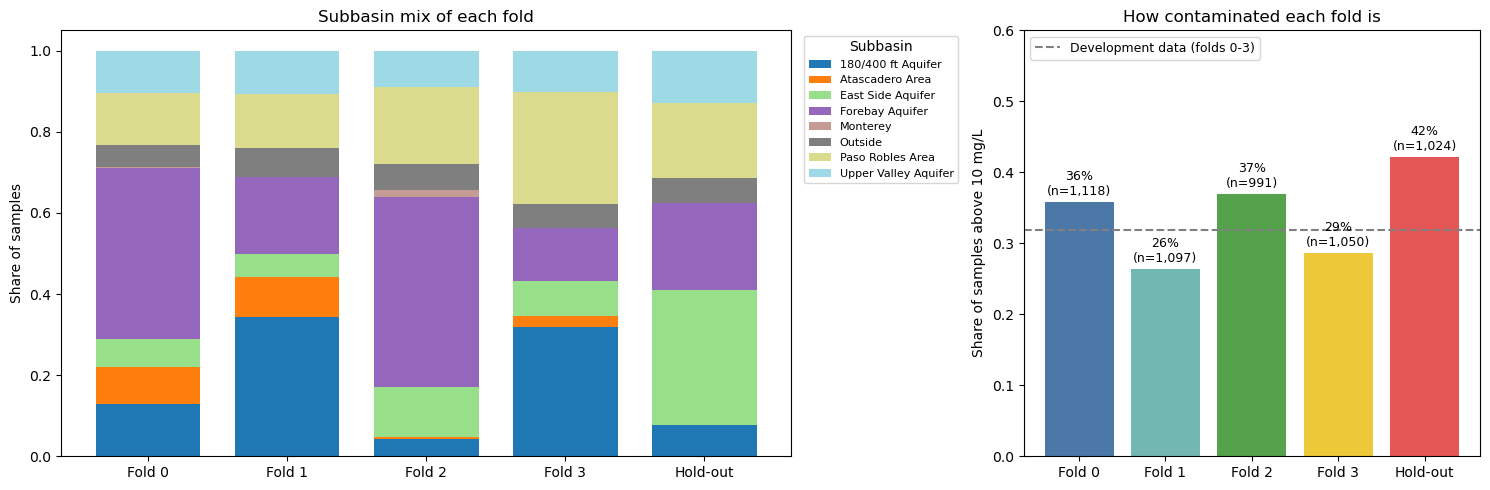

In [10]:
# 2. What each fold contains: subbasin mix and share of samples above 10 mg/L
composition = pd.crosstab(data["fold_label"], data["subbasin_name"], normalize="index").reindex(fold_order)
exceedance = data.groupby("fold_label")["exceeds"].mean().reindex(fold_order)
n_samples = data["fold_label"].value_counts().reindex(fold_order)

fig, axs = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1.6, 1]})
composition.plot(kind="bar", stacked=True, ax=axs[0], colormap="tab20", width=0.75)
axs[0].set(ylabel="Share of samples", xlabel="", title="Subbasin mix of each fold")
axs[0].legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8, title="Subbasin")
axs[0].tick_params(axis="x", rotation=0)

bars = axs[1].bar(fold_order, exceedance, color=[fold_colors[f] for f in fold_order])
for bar, rate, n in zip(bars, exceedance, n_samples):
    axs[1].text(bar.get_x() + bar.get_width() / 2, rate + 0.01, f"{rate:.0%}\n(n={n:,})", ha="center", fontsize=9)
axs[1].axhline(data.loc[~data["holdout"], "exceeds"].mean(), color="gray", linestyle="--",
               label="Development data (folds 0-3)")
axs[1].set(ylabel=f"Share of samples above {THRESHOLD_MG_L} mg/L", ylim=(0, 0.6),
           title="How contaminated each fold is")
axs[1].legend(loc="upper left", fontsize=9)
plt.tight_layout()
if RUN_FINAL_EVALUATION:
    plt.savefig(OUT_DIR / "folds_composition.png", dpi=150, bbox_inches="tight")
plt.show()

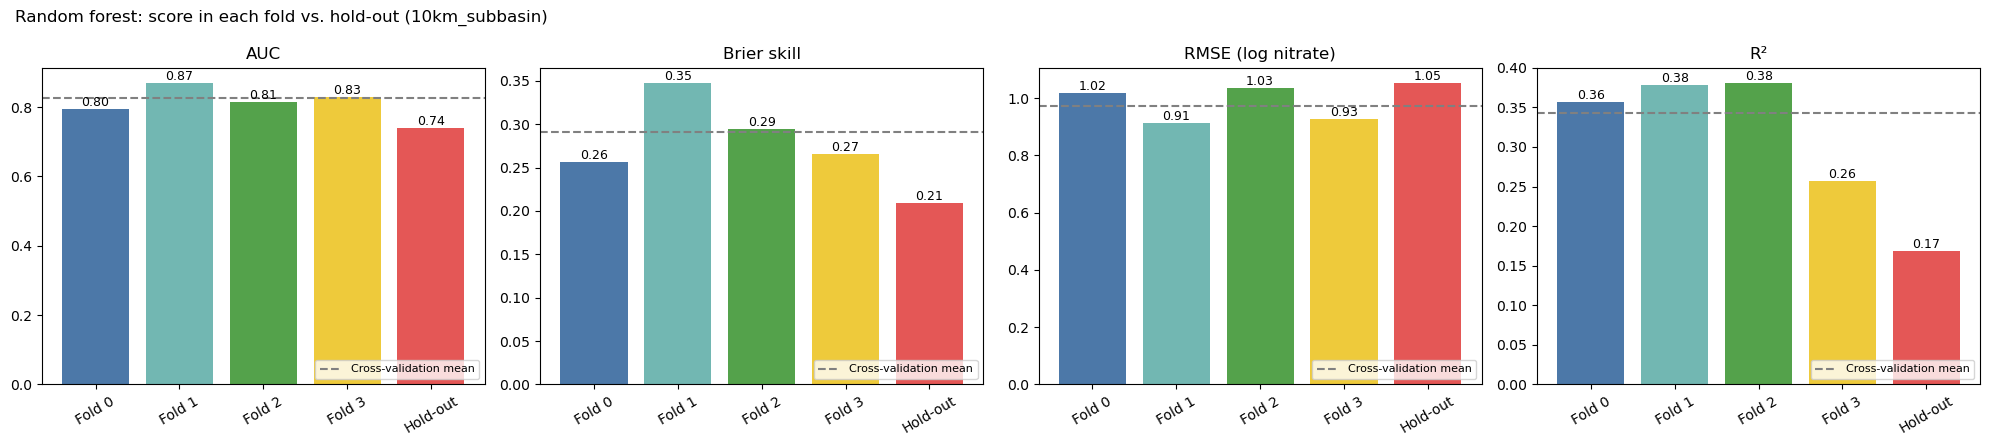

In [11]:
# 3. Random forest score in each cross-validation fold and in the hold-out
rf_cv = runs[runs["model"] == "Random forest"].copy()
rf_cv["fold_label"] = "Fold " + rf_cv["fold"].astype(int).astype(str)
holdout_scores = final_scores.set_index(["task", "model"]).loc[
    [("classification", "Random forest"), ("regression", "Random forest")]]
holdout_name = "Hold-out" if RUN_FINAL_EVALUATION else "Stand-in (dry run)"

panels = [("classification", "auc", "AUC"), ("classification", "brier_skill", "Brier skill"),
          ("regression", "rmse_log", "RMSE (log nitrate)"), ("regression", "r2", "R²")]
fig, axs = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, (task, metric, name) in zip(axs, panels):
    cv = rf_cv[rf_cv["task"] == task].sort_values("fold")
    labels = list(cv["fold_label"]) + [holdout_name]
    values = list(cv[metric]) + [holdout_scores.loc[(task, "Random forest"), metric]]
    colors = [fold_colors.get(l, "#999999") for l in cv["fold_label"]] + [fold_colors["Hold-out"]]
    bars = ax.bar(labels, values, color=colors)
    for bar, value in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width() / 2, value, f"{value:.2f}", ha="center", va="bottom", fontsize=9)
    ax.axhline(cv[metric].mean(), color="gray", linestyle="--", label="Cross-validation mean")
    ax.set_title(name)
    ax.tick_params(axis="x", rotation=30)
    ax.legend(fontsize=8, loc="lower right")
fig.suptitle(f"Random forest: score in each fold vs. hold-out ({SPLIT})", x=0.01, ha="left")
plt.tight_layout()
if RUN_FINAL_EVALUATION:
    plt.savefig(OUT_DIR / "folds_performance.png", dpi=150, bbox_inches="tight")
plt.show()

In [12]:
# 4. Hold-out performance by subbasin (subbasins with at least 50 hold-out samples)
test_named = test.merge(data[["gm_well_id", "gm_samp_collection_date", "subbasin_name"]].drop_duplicates(),
                        on=["gm_well_id", "gm_samp_collection_date"], how="left")
test_named["rf_probability"] = class_probs["Random forest"]
test_named["rf_called"] = (test_named["rf_probability"] >= THRESHOLD).astype(int)

rows = []
for name, group in test_named.groupby("subbasin_name"):
    if len(group) < 50:
        continue
    both_classes = group["exceeds"].nunique() == 2
    rows.append({
        "subbasin": name, "samples": len(group),
        "share_above_10": group["exceeds"].mean(),
        "auc": roc_auc_score(group["exceeds"], group["rf_probability"]) if both_classes else np.nan,
        "recall": recall_score(group["exceeds"], group["rf_called"], zero_division=0) if group["exceeds"].any() else np.nan,
        "mean_predicted": group["rf_probability"].mean(),
    })
by_subbasin = pd.DataFrame(rows).sort_values("samples", ascending=False)
display(by_subbasin.round(2))

,subbasin,samples,share_above_10,auc,recall,mean_predicted
1,East Side Aquifer,341,0.64,0.58,0.87,0.55
2,Forebay Aquifer,220,0.45,0.57,0.69,0.48
4,Paso Robles Area,190,0.07,0.64,0.00,0.07
5,Upper Valley Aquifer,131,0.57,0.49,0.76,0.49
0,180/400 ft Aquifer,79,0.29,0.67,0.26,0.27
3,Outside,63,0.06,0.55,0.00,0.07


## 5c. Feature importance

How much the final random forest classifier relies on each feature: each feature is shuffled in the test fold and the drop in AUC is measured (permutation importance, 20 repeats). The subbasin indicator columns are shuffled together as one feature.

Hold-out AUC with no shuffling: 0.741


,feature,auc_drop_mean,auc_drop_std,impurity_importance
0,subbasin,0.0183,0.0041,0.0698
1,soil_slopegradwta,0.0070,0.0027,0.0572
2,pct_veg_berry_500m,0.0068,0.0047,0.0696
3,soil_hydgrpdcd_pct_a,0.0062,0.0009,0.0246
4,pct_vineyard_500m,0.0052,0.0014,0.0237
5,soil_aws0150wta,0.0033,0.0015,0.0343
6,crop_cycles_500m,0.0026,0.0027,0.0528
7,historical_mean_annual_precip_mm,0.0022,0.0043,0.0627
8,pct_urban_500m,0.0022,0.0005,0.0117
9,soil_hydgrpdcd_pct_c,0.0010,0.0009,0.0250


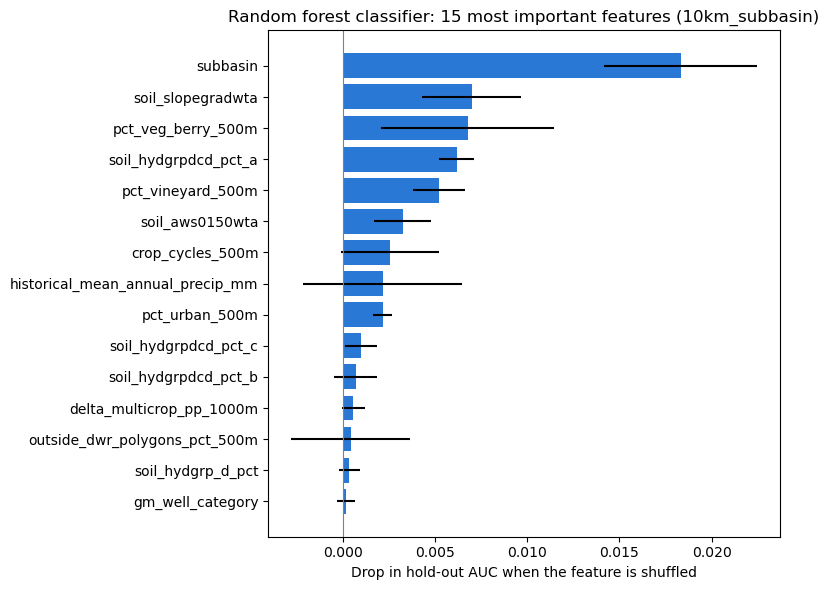

In [13]:
from joblib import Parallel, delayed

# Permutation importance: shuffle one feature (or one group of features) in the test fold and measure how much the hold-out AUC drops. A large drop means the model relies on that feature. The subbasin indicator columns are shuffled together, as one feature, since they describe one variable.
N_REPEATS = 20

rf = final_models["Random forest classifier"]
subbasin_cols = [f for f in FEATURES if f.startswith("subbasin_")]
groups = {f: [f] for f in FEATURES if f not in subbasin_cols}
if subbasin_cols:
    groups["subbasin"] = subbasin_cols

X_test, y_test = test[FEATURES], test["exceeds"]
base_auc = roc_auc_score(y_test, rf.predict_proba(X_test)[:, 1])


def auc_drops(cols, seed):
    """Drop in AUC for each of N_REPEATS shuffles of these columns (shuffled together)."""
    rng = np.random.default_rng(seed)
    drops = []
    for _ in range(N_REPEATS):
        shuffled = X_test.copy()
        shuffled[cols] = shuffled[cols].to_numpy()[rng.permutation(len(shuffled))]
        drops.append(base_auc - roc_auc_score(y_test, rf.predict_proba(shuffled)[:, 1]))
    return drops


# One feature per CPU core; each feature has its own seed, so the result does not depend on the number of cores
results = Parallel(n_jobs=-1)(delayed(auc_drops)(cols, seed) for seed, cols in enumerate(groups.values()))

# Impurity importance (how much each feature's splits reduce impurity in training), for comparison;
# it tends to favour continuous features, so the permutation result is the one to report
impurity = pd.Series(rf.feature_importances_, index=FEATURES)
if subbasin_cols:
    impurity["subbasin"] = impurity[subbasin_cols].sum()

importance = (pd.DataFrame({
    "feature": list(groups),
    "auc_drop_mean": [np.mean(d) for d in results],
    "auc_drop_std": [np.std(d) for d in results]
}).assign(impurity_importance=lambda d: d["feature"].map(impurity))
.sort_values("auc_drop_mean", ascending=False).reset_index(drop=True))
print(f"Hold-out AUC with no shuffling: {base_auc:.3f}")
display(importance.head(15).round(4))

INTERPRETABILITY = paths.FIGURES["interpretability"]
INTERPRETABILITY.mkdir(parents=True, exist_ok=True)
importance.to_csv(INTERPRETABILITY / f"permutation_importance_classifier_{TAG}.csv", index=False)

top = importance.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top["feature"], top["auc_drop_mean"], xerr=top["auc_drop_std"], color="#2a78d6")
ax.axvline(0, color="gray", linewidth=0.8)
ax.set(xlabel="Drop in hold-out AUC when the feature is shuffled", title=f"Random forest classifier: 15 most important features ({SPLIT})")
plt.tight_layout()
plt.savefig(INTERPRETABILITY / f"permutation_importance_classifier_{TAG}.png", dpi=150, bbox_inches="tight")
plt.show()


## 6. Conclusions

- **Classification (random forest):** hold-out AUC = 0.741 (cross-validation 0.827, range 0.796–0.871 across folds), Brier skill = 0.209 (0.291). At the agreed threshold of 0.4, the model detects 74% of samples exceeding 10 mg/L (recall), and 59% of the samples it flags actually exceed the limit (precision); F1 = 0.654.
- **Regression (random forest):** hold-out RMSE (log) = 1.053 vs. 1.237 for the dummy baseline, a 15% reduction (19% in cross-validation); R² = 0.170 (cross-validation 0.343).
- **Generalization:** hold-out performance is lower than in cross-validation. The hold-out fold is a harder area: it contains about half of the East Side Aquifer samples, the most contaminated subbasin, and 42% of its samples exceed 10 mg/L versus 32% in the development data. The dummy regressor's negative R² (−0.15) on the hold-out reflects this shift in nitrate levels. Relative to the baseline, the random forest still improves predictions by a similar margin as in cross-validation.
- **Caveats:** a single hold-out fold covers a limited set of areas, so its score is more uncertain than the four-fold cross-validation mean; both should be reported. Performance applies to the Salinas Valley; transfer to other basins was not tested.

The fitted final models are saved in `data/models/` (local) for the risk map notebook.